# Task 16 - Sentiment Score Feature (VADER + fine-tuned deep learning)

**Goal:** engineer a normalised `sentiment_score` from review text using a lexicon model (VADER), a classical domain model (TF-IDF + logistic regression) and a **fine-tuned transformer (DistilBERT)**, then combine them into one 0-1 feature.

**Input:** newest available dataset in `data/processed/` that contains the review text
**Outputs:** `data/processed/womens_clothing_sentiment_features.csv`, `reports/task_16_sentiment_model_comparison.csv`, `reports/task_16_analysis_status.csv`

**Training labels (silver labels):** rating >= 4 -> positive, rating <= 2 -> negative, rating 3 is excluded from training (the model still scores it, which is how neutral reviews land mid-scale).

**Leakage note:** supervised models are trained on labels derived from `Rating`. TF-IDF scores are *out-of-fold*, so they are leak-free. The transformer is trained on a sample, so rows it saw are flagged `sentiment_dl_in_train = 1`; evaluate only on the held-out rows (done below) and be careful when using `sentiment_score` to predict `Rating`.

**Compute:** fine-tuning runs on CPU in ~15-40 min (GPU: a few minutes). Set `FINE_TUNE_TRANSFORMER = False` to skip it; the notebook then uses the TF-IDF model as the domain model.

In [9]:
import re, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

def find_project_root():
    """Walk up from the notebook folder until a folder containing data/processed is found."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed").exists():
            return cand
    return start.parent

ROOT = find_project_root()
PROC = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
PROC.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def pick(df, *candidates, required=True):
    """Return the real column name matching any candidate (ignores case, spaces, underscores)."""
    lookup = {_norm(c): c for c in df.columns}
    for cand in candidates:
        if _norm(cand) in lookup:
            return lookup[_norm(cand)]
    if required:
        raise KeyError(f"None of {candidates} found. Columns: {list(df.columns)}")
    return None

def load_first(*paths, require_any=None):
    """Load the first existing CSV (optionally one that has at least one of the required columns)."""
    for p in paths:
        if not Path(p).exists():
            continue
        d = pd.read_csv(p)
        d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
        if require_any and not any(_norm(c) in {_norm(x) for x in d.columns} for c in require_any):
            print(f"Skipped {Path(p).name}: none of {require_any} present")
            continue
        print(f"Loaded: {Path(p).name}  shape={d.shape}")
        return d, Path(p)
    raise FileNotFoundError("No usable file found among: " + ", ".join(str(p) for p in paths))

# Newest cumulative dataset first; each task falls back to an earlier file if a later one does not exist yet.
CHAIN = ["womens_clothing_high_cardinality_encoded.csv", "womens_clothing_engagement_features.csv",
         "womens_clothing_sentiment_features.csv", "womens_clothing_age_segmented.csv",
         "womens_clothing_review_text_features.csv", "womens_clothing_market_basket_features.csv",
         "womens_clothing_product_text_features.csv", "womens_clothing_product_tag_features.csv",
         "womens_clothing_product_segmented.csv", "womens_clothing_final.csv"]

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

# ---------------- configuration ----------------
FINE_TUNE_TRANSFORMER = True            # needs: pip install torch transformers
MODEL_NAME = "distilbert-base-uncased"  # try "bert-base-uncased" on GPU
N_TRAIN = 8000                          # labelled reviews used for fine-tuning (CPU friendly)
EPOCHS, BATCH_SIZE, MAX_LEN, LR = 2, 32, 128, 2e-5
W_DEEP, W_VADER = 0.6, 0.4              # ensemble weights (deep/domain model vs VADER)

Project root: D:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project


In [10]:
for p in sorted((ROOT / "data").rglob("*.csv")):
    cols = pd.read_csv(p, nrows=0).columns
    n = len(pd.read_csv(p, usecols=[0]))
    has = any(_norm(c) in {"reviewtext", "review"} for c in cols)
    print(f"{str(p.relative_to(ROOT)):65s} rows={n:>6,}  review_text={has}")

data\interim\womens_clothing_cleaned.csv                          rows= 1,539  review_text=False
data\interim\womens_clothing_standardized.csv                     rows= 1,539  review_text=False
data\processed\womens_clothing_categorical_encoded.csv            rows= 1,539  review_text=False
data\processed\womens_clothing_final.csv                          rows= 1,539  review_text=False
data\processed\womens_clothing_product_segmented.csv              rows= 1,539  review_text=False
data\processed\womens_clothing_product_tag_features.csv           rows= 1,539  review_text=False
data\processed\womens_clothing_product_text_features.csv          rows= 1,539  review_text=False
data\processed\womens_clothing_scaled.csv                         rows= 1,539  review_text=False
data\raw\womens_clothing.csv                                      rows= 1,573  review_text=False


## 1. Load data

In [11]:
# Load the newest usable processed CSV. This project is product/catalog based,
# so fall back to product text, title, or tags when review-text columns are absent.
candidates = [PROC / n for n in CHAIN]
candidates += sorted(PROC.glob("*.csv"), reverse=True)
candidates += [ROOT / "data" / "interim" / "womens_clothing_standardized.csv",
               ROOT / "data" / "interim" / "womens_clothing_cleaned.csv",
               ROOT / "data" / "raw" / "womens_clothing.csv"]
df, src = load_first(*candidates)
rating_col = pick(df, "Rating")
text_col = pick(df, "Review Text", "Review", "ReviewText", "product_text", "Product Text", required=False)
title_col = pick(df, "Title", "Review Title", "title_orig", required=False)
rec_col    = pick(df, "Recommended IND", "Recommended", required=False)

body = df[text_col].astype("string").fillna("").str.strip() if text_col else pd.Series("", index=df.index)
title = df[title_col].astype("string").fillna("").str.strip() if title_col else pd.Series("", index=df.index)
tags_col = pick(df, "tags", "product_tags", required=False)
tags = df[tags_col].astype("string").fillna("").str.strip() if tags_col else pd.Series("", index=df.index)
if text_col is None:
    body = title.where(title.str.len() > 0, tags)
df["sentiment_text"] = (title + ". " + body).str.strip(". ").str.strip()
has_text = df["sentiment_text"].str.len() > 0
df["sentiment_has_text"] = has_text.astype(int)

y_silver = pd.Series(np.nan, index=df.index)
y_silver[df[rating_col] >= 4] = 1
y_silver[df[rating_col] <= 2] = 0
labelled = has_text & y_silver.notna()
print(f"Rows: {len(df):,} | with text: {has_text.sum():,} | labelled (rating 1-2 or 4-5): {labelled.sum():,} "
      f"| positive share: {y_silver[labelled].mean():.2%}")

Loaded: womens_clothing_product_text_features.csv  shape=(1539, 49)
Rows: 1,539 | with text: 1,539 | labelled (rating 1-2 or 4-5): 597 | positive share: 97.82%


## 2. Model 1 - VADER (lexicon baseline, compound in [-1, 1])

In [12]:
analyzer = SentimentIntensityAnalyzer()
df["vader_compound"] = [analyzer.polarity_scores(t)["compound"] if t else 0.0 for t in df["sentiment_text"]]
print("Spearman(VADER, rating) =", round(stats.spearmanr(df.loc[has_text, "vader_compound"], df.loc[has_text, rating_col])[0], 3))

Spearman(VADER, rating) = 0.102


## 3. Model 2 - TF-IDF + logistic regression (domain-trained, out-of-fold)

Every labelled review is scored by a model that never saw it (5-fold). Reviews with rating 3 or no label are scored by a model fit on all labelled data.

In [13]:
def make_tfidf_lr():
    from sklearn.pipeline import make_pipeline
    return make_pipeline(TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5, max_features=30000, sublinear_tf=True),
                         LogisticRegression(max_iter=1000, C=2.0))

idx_l = df.index[labelled]
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
oof = cross_val_predict(make_tfidf_lr(), df.loc[idx_l, "sentiment_text"], y_silver[idx_l].astype(int), cv=cv, method="predict_proba")[:, 1]
df["tfidf_sentiment_prob"] = np.nan
df.loc[idx_l, "tfidf_sentiment_prob"] = oof
full_lr = make_tfidf_lr().fit(df.loc[idx_l, "sentiment_text"], y_silver[idx_l].astype(int))
rest = df.index[has_text & df["tfidf_sentiment_prob"].isna()]
if len(rest): df.loc[rest, "tfidf_sentiment_prob"] = full_lr.predict_proba(df.loc[rest, "sentiment_text"])[:, 1]
df.loc[~has_text, "tfidf_sentiment_prob"] = 0.5
print("TF-IDF OOF AUC:", round(roc_auc_score(y_silver[idx_l], oof), 4))

TF-IDF OOF AUC: 0.8998


## 4. Model 3 - fine-tuned transformer (DistilBERT)

A pre-trained language model is fine-tuned for 2 epochs on a stratified sample of labelled reviews, validated on a held-out slice, then used to score every review. If `torch`/`transformers` are missing or the model cannot be downloaded, the notebook falls back to the TF-IDF model automatically.

In [14]:
dl_available, dl_error = False, None
df["dl_sentiment_prob"] = np.nan
df["sentiment_dl_in_train"] = 0
dl_val_metrics = {}

def finetune_and_score():
    import math, torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    torch.manual_seed(RANDOM_STATE)
    device = "cuda" if torch.cuda.is_available() else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
    print("Device:", device)

    lab = df.loc[labelled]
    n = min(N_TRAIN, len(lab))
    samp, _ = train_test_split(lab.index, train_size=n, stratify=y_silver[lab.index], random_state=RANDOM_STATE)
    tr_idx, va_idx = train_test_split(samp, test_size=0.15, stratify=y_silver[samp], random_state=RANDOM_STATE)

    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * math.ceil(len(tr_idx) / BATCH_SIZE)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    X_tr, y_tr = df.loc[tr_idx, "sentiment_text"].tolist(), y_silver[tr_idx].astype(int).values

    def predict(texts):
        model.eval(); order = np.argsort([len(t) for t in texts]); out = np.zeros(len(texts))
        with torch.no_grad():
            for i in range(0, len(texts), 64):
                b = order[i:i + 64]
                enc = tok([texts[j] for j in b], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
                out[b] = torch.softmax(model(**enc).logits, dim=-1)[:, 1].cpu().numpy()
        return out

    rng = np.random.default_rng(RANDOM_STATE)
    for ep in range(EPOCHS):
        model.train(); perm = rng.permutation(len(X_tr)); total = 0
        for i in range(0, len(perm), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            enc = tok([X_tr[j] for j in b], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
            loss = model(**enc, labels=torch.tensor(y_tr[b]).to(device)).loss
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad(); total += loss.item() * len(b)
        print(f"epoch {ep + 1}/{EPOCHS} train loss {total / len(perm):.4f}")

    pv = predict(df.loc[va_idx, "sentiment_text"].tolist()); yv = y_silver[va_idx].astype(int).values
    metrics = {"val_auc": roc_auc_score(yv, pv), "val_accuracy": accuracy_score(yv, pv > 0.5), "val_f1": f1_score(yv, pv > 0.5), "n_val": len(va_idx)}
    probs = pd.Series(np.nan, index=df.index)
    probs[has_text] = predict(df.loc[has_text, "sentiment_text"].tolist())
    return probs, tr_idx, va_idx, metrics

if FINE_TUNE_TRANSFORMER:
    try:
        probs, tr_idx, va_idx, dl_val_metrics = finetune_and_score()
        df["dl_sentiment_prob"] = probs
        df.loc[~has_text, "dl_sentiment_prob"] = 0.5
        df.loc[list(tr_idx) + list(va_idx), "sentiment_dl_in_train"] = 1
        dl_available = True
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in dl_val_metrics.items()})
    except Exception as e:                       # missing libs, no internet, out of memory ...
        dl_error = repr(e)
        print("Transformer step skipped ->", dl_error)
else:
    print("FINE_TUNE_TRANSFORMER = False -> using TF-IDF model as the domain model")

Device: cpu
Transformer step skipped -> ValueError('train_size=597 should be either positive and smaller than the number of samples 597 or a float in the (0, 1) range')


## 5. Combine and normalise

1. Domain model probability -> signed score `2p - 1` in [-1, 1] (transformer if available, otherwise TF-IDF).
2. Ensemble: `sentiment_raw = W_DEEP * domain + W_VADER * VADER`.
3. **Normalise:** robust min-max (1st-99th percentile clip) to 0-1 -> `sentiment_score`, plus a z-score version for linear models.
4. Reviews without text get the neutral value (0.5, z = 0) and `sentiment_has_text = 0`.

In [15]:
domain_prob = df["dl_sentiment_prob"] if dl_available else df["tfidf_sentiment_prob"]
domain_name = f"fine-tuned {MODEL_NAME}" if dl_available else "TF-IDF + LogReg"
df["sentiment_domain_signed"] = 2 * domain_prob - 1
df["sentiment_raw"] = W_DEEP * df["sentiment_domain_signed"] + W_VADER * df["vader_compound"]
df.loc[~has_text, "sentiment_raw"] = 0.0

lo, hi = df.loc[has_text, "sentiment_raw"].quantile([0.01, 0.99])
df["sentiment_score"] = ((df["sentiment_raw"].clip(lo, hi) - lo) / (hi - lo)).clip(0, 1)
mu, sd = df.loc[has_text, "sentiment_raw"].mean(), df.loc[has_text, "sentiment_raw"].std()
df["sentiment_score_z"] = (df["sentiment_raw"] - mu) / sd
df.loc[~has_text, ["sentiment_score", "sentiment_score_z"]] = [0.5, 0.0]
df["sentiment_label"] = pd.cut(df["sentiment_score"], [-0.01, 0.4, 0.6, 1.01], labels=["negative", "neutral", "positive"]).astype(str)
df["sentiment_model_used"] = domain_name
print("Domain model:", domain_name)
df[["sentiment_text", "vader_compound", "tfidf_sentiment_prob", "dl_sentiment_prob", "sentiment_score", "sentiment_label"]].head(8)

Domain model: TF-IDF + LogReg


,sentiment_text,vader_compound,tfidf_sentiment_prob,dl_sentiment_prob,sentiment_score,sentiment_label
0,2020 Summer Vintage Flamingo Print Pajamas Se...,0.1531,0.989284,NaN,0.471090,neutral
1,SSHOUSE Summer Casual Sleeveless Soirée Party ...,0.9300,0.984153,NaN,0.970746,positive
2,2020 Nouvelle Arrivée Femmes Printemps et Été ...,0.0000,0.976266,NaN,0.345009,negative
3,Hot Summer Cool T-shirt pour les femmes Mode T...,0.9501,0.986195,NaN,0.987954,positive
4,Femmes Shorts d'été à lacets taille élastique ...,0.0000,0.971009,NaN,0.334662,negative
5,Plus la taille d'été femmes décontracté sans m...,0.0000,0.942052,NaN,0.277661,negative
6,Women Fashion Loose Lace Blouse Blouse V Neck ...,0.4588,0.980975,NaN,0.655315,positive
7,Robe tunique ample femme Robe d'été Robe en je...,0.0000,0.985640,NaN,0.363461,negative


## 6. Evaluation (leak-aware)

In [16]:
# For the transformer, only rows it never saw are used. TF-IDF and VADER are leak-free everywhere.
eval_mask = labelled & (df["sentiment_dl_in_train"] == 0)
yv = y_silver[eval_mask].astype(int)
cands = {"VADER": df["vader_compound"], "TF-IDF + LogReg (OOF)": df["tfidf_sentiment_prob"],
         "Ensemble sentiment_score": df["sentiment_score"]}
if dl_available: cands[f"Fine-tuned {MODEL_NAME}"] = df["dl_sentiment_prob"]
rows = []
for name, s in cands.items():
    rows.append({"model": name, "n_eval": int(eval_mask.sum()), "auc_pos_vs_neg": roc_auc_score(yv, s[eval_mask]),
                 "spearman_vs_rating": stats.spearmanr(s[has_text & (df["sentiment_dl_in_train"] == 0)], df.loc[has_text & (df["sentiment_dl_in_train"] == 0), rating_col])[0]})
comparison = pd.DataFrame(rows).round(4)
comparison

,model,n_eval,auc_pos_vs_neg,spearman_vs_rating
0,VADER,597,0.4249,0.1016
1,TF-IDF + LogReg (OOF),597,0.8998,0.1546
2,Ensemble sentiment_score,597,0.5304,0.1442


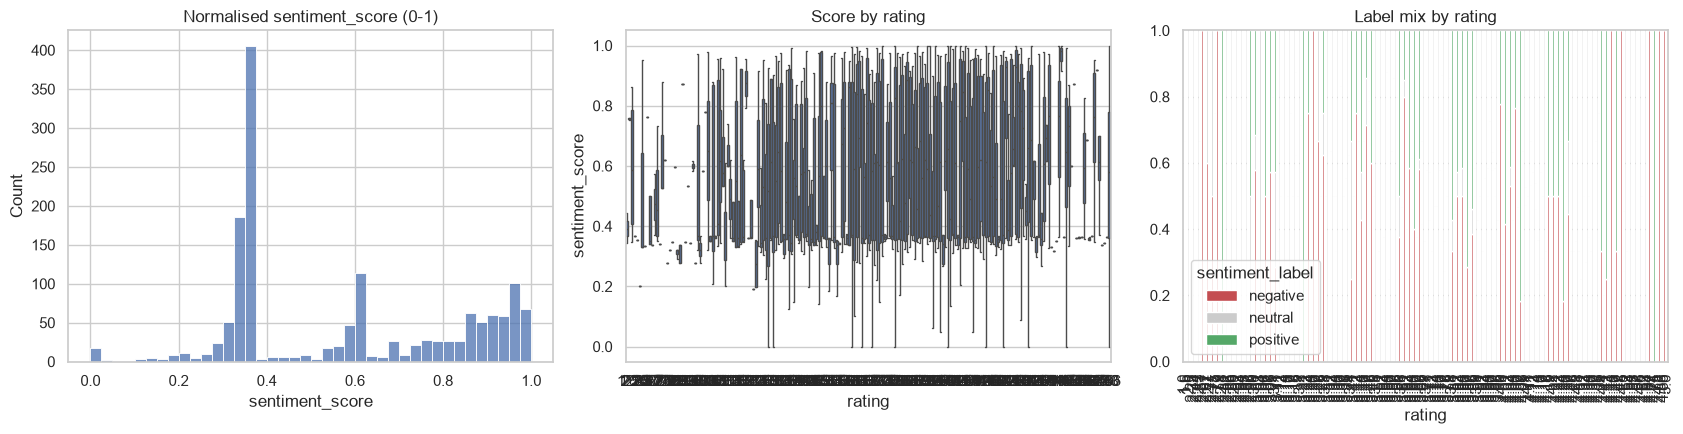

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df.loc[has_text, "sentiment_score"], bins=40, ax=ax[0], color="#4c72b0"); ax[0].set_title("Normalised sentiment_score (0-1)")
sns.boxplot(data=df[has_text], x=rating_col, y="sentiment_score", ax=ax[1], showfliers=False); ax[1].set_title("Score by rating")
pd.crosstab(df.loc[has_text, rating_col], df.loc[has_text, "sentiment_label"], normalize="index")[["negative", "neutral", "positive"]].plot.bar(stacked=True, ax=ax[2], color=["#c44e52", "#cccccc", "#55a868"])
ax[2].set_title("Label mix by rating"); plt.tight_layout(); plt.show()

In [18]:
# Examples where the model and the star rating disagree - useful for spotting sarcasm / data issues
dis = df[has_text & (df[rating_col] <= 2) & (df["sentiment_score"] > 0.7)].head(5)
dis2 = df[has_text & (df[rating_col] == 5) & (df["sentiment_score"] < 0.3)].head(5)
pd.concat([dis, dis2])[[rating_col, "sentiment_score", "sentiment_text"]]

,rating,sentiment_score,sentiment_text
41,1.5,0.759960,Mode féminine été bretelles spaghetti imprimé ...
170,2.0,0.841027,Plus la taille des femmes de la mode lâche déc...
217,2.0,0.766090,S-5XL Nouvelle Mode Femmes Tops Blouse Sans Ma...
287,2.0,0.722962,S-5XL Nouvelle Mode Femmes Tops Blouse Sans Ma...
667,2.0,0.863715,"Robe d'été à lacets pour femmes, mode sexy, co..."
5,5.0,0.277661,Plus la taille d'été femmes décontracté sans m...
551,5.0,0.240551,Femmes Robes D'été De Mode Col En V Dos Nu Rob...
1097,5.0,0.000000,2020 Fashion Trend Butterfly Print Masks Stree...
1132,5.0,0.249530,Femmes Robes D'été De Mode Col En V Dos Nu Rob...
1169,5.0,0.003370,Women Fashion Vintage Animal Dragonfly Owl Pri...


## 7. Save outputs

In [19]:
drop_cols = ["sentiment_text", "sentiment_domain_signed"]
out = df.drop(columns=drop_cols)
out_path = PROC / "womens_clothing_sentiment_features.csv"
out.to_csv(out_path, index=False)

comp_save = comparison.copy()
comp_save["domain_model_used"] = domain_name
for k, v in dl_val_metrics.items(): comp_save[f"transformer_{k}"] = round(v, 4) if isinstance(v, float) else v
comp_save.to_csv(REPORTS / "task_16_sentiment_model_comparison.csv", index=False)

new_cols = [c for c in out.columns if c not in pd.read_csv(src, nrows=1).columns]
status = pd.DataFrame([{
    "task": "Task 16 - Sentiment Score Feature", "status": "completed",
    "run_at": datetime.now().isoformat(timespec="seconds"), "input_file": src.name,
    "rows_in": len(df), "rows_out": len(out), "rows_with_text": int(has_text.sum()),
    "domain_model": domain_name, "transformer_error": dl_error or "",
    "weights_deep_vader": f"{W_DEEP}/{W_VADER}", "columns_added": len(new_cols),
    "new_columns": ";".join(new_cols), "output_dataset": out_path.name}])
status.to_csv(REPORTS / "task_16_analysis_status.csv", index=False)
status.T

,0
task,Task 16 - Sentiment Score Feature
status,completed
run_at,2026-11-23T16:49:48
input_file,womens_clothing_product_text_features.csv
rows_in,1539
rows_out,1539
rows_with_text,1539
domain_model,TF-IDF + LogReg
transformer_error,ValueError('train_size=597 should be either po...
weights_deep_vader,0.6/0.4
